# 12b · 新架构：一个模型同时看图像和笔迹

**出发点。**notebook 11 的融合是"两个模型各自训练，最后把概率加权平均"（晚期融合）。它很有效（错误减少约 40%），但有三个可以改进的地方：

1. **两个模型互相看不见。**图像模型不知道笔是怎么走的，轨迹模型不知道墨迹最后长什么样；只在最后一步合并概率。如果某个判断需要"这一笔经过的地方，墨迹是不是封口的"，两个模型都单独做不到。
2. **固定的权重。**所有样本都用同一个 $w = 0.55$。直觉上，轨迹模型很犹豫、图像模型很确定时，应该更信图像，反过来也一样。
3. **上线要跑两个模型**，体积翻倍。

这一本设计并比较四种新结构。前三种需要**训练时同时有图像和笔迹**的数据，而最大的训练集 MNIST 只有图像。所以先要解决这个问题。

### 关键设计：没有笔迹的样本怎么办

训练时每个样本带一个"笔迹可用"标记 `avail`：MNIST 和合成的骨架笔画 `avail = 0`，笔迹部分全部填 0；真实的触控笔样本和模板笔迹 `avail = 1`。此外，有笔迹的样本也**以 30% 的概率随机把笔迹藏起来**（ModDrop [34]）。这样同一个模型既学会了利用笔迹，也学会了在没有笔迹时只看图像。这在游戏里也有用：比如以后输入方式变了、或者笔迹异常时，模型可以退回只看图。

### 四种结构

| 结构 | 思路 | 来源 |
|---|---|---|
| **方向图 CNN**（`ordermap_cnn`） | 不加第二个网络，而是给图像加 4 个通道：笔经过这个像素时的**方向**（x、y 两个分量）、经过的**先后**（整条路径上的位置，0 到 1）、以及 `avail`。就是上线的 CNN，只是输入从 1 个通道变成 5 个。大小几乎不变（10.8 万参数）。 | 把笔画方向分解成多张特征图是在线中文识别的经典做法 [31, 32]；加上"先后"通道、并配合 ModDrop 让同一个网络也能读普通图像，是我们为这个游戏设计的组合 |
| **双流联合训练**（`dual_stream`） | 图像 CNN 和 notebook 11 的轨迹 1D CNN 放在一个模型里**一起训练**，两边的特征拼起来再分类（中期融合）。 | 多模态学习的标准做法 |
| **交叉注意力**（`ink_glance`） | 笔迹的 16 段各自去"看"图像特征图上的 49 个格子（cross-attention [33]），也就是每一段笔迹可以问"我经过的地方墨迹长什么样"。 | 我们的设计；注意力机制见 [33] |
| **门控融合**（`gated fusion`） | 仍然是两个独立模型（09 的图像 C + 11 的轨迹模型），但融合权重 $w$ 按样本变化：由两个模型各自的把握程度（最大概率、熵）和是否一致，通过 6 个参数算出来。 | 门控多模态单元 [35] 的极简版本 |

**公平比较。**训练预算和 09 相同（16 轮 × 470 步 × 约 128，Adam + 余弦退火，label smoothing 0.1）。数据：MNIST 35%、骨架笔画 35%、真实触控笔 20%（每个样本 5 份，和 09 完全相同的图像）、模板笔迹 10%。对照组是 notebook 09 的图像模型 C 和 notebook 11 的晚期融合。每种结构两个种子。验证集挑选，测试集只报告。

In [1]:
import json, sys, time
from multiprocessing import Pool
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from scipy.optimize import minimize

from fingermath import archs, datasets, evaluate, models, multiview, recipe, ship, synth, trajectory

REAL = Path('../cache/real'); RAW = Path('../cache/raw'); RESULTS = Path('../results'); MODEL_DIR = Path('../cache/models')
SEEDS = recipe.SEEDS
plt.rcParams['figure.dpi'] = 110

meta, x_real = recipe.real_meta()
y = meta.label.to_numpy()
SPLITS = recipe.eval_splits(meta)
strokes = recipe.strokes()
for a, i in zip(trajectory.corr_strokes_in_order(RAW / 'corr'), np.flatnonzero(meta.source == 'corr')):
    strokes[i] = a                                     # Corr strokes in writing order (notebook 10)

## 1. 数据：每个样本的三种"视图"

`multiview.views` 从同一组笔画同时生成：游戏的 28×28 图像、和图像逐像素对齐的方向图（3 个通道）、64 点的轨迹编码。方向图和图像用**同一支笔、同一套裁剪缩放和重心平移**生成，所以完全对齐。先检查：生成的图像和 notebook 09 训练用的图像完全相同。

In [2]:
VIEWS = REAL / 'views12b.npz'
if VIEWS.exists():
    V = dict(np.load(VIEWS))
else:
    V = {}
    k_tr = np.flatnonzero((meta.source == 'pendigits') & (meta.split == 'train'))
    with Pool() as pool:
        r = pool.starmap(multiview.pen_views, [(strokes[i], 1000 + j) for j, i in enumerate(k_tr)], chunksize=20)
        V['pen_img'], V['pen_om'], V['pen_tr'] = [np.concatenate(v) for v in zip(*r)]
        V['pen_y'] = np.repeat(y[k_tr], 5)
        rng = np.random.default_rng(12)
        tmpl, ty = [], []
        for w in range(1000):                          # 1000 template writers x 10 digits x 3
            writer = synth.make_writer(rng)
            for dgt in np.repeat(np.arange(10), 3):
                tmpl.append(synth.template_strokes(int(dgt), writer, rng)); ty.append(dgt)
        r = pool.map(multiview.views, tmpl, chunksize=50)
        V['tmpl_img'], V['tmpl_om'], V['tmpl_tr'] = [np.stack(v) for v in zip(*r)]
        V['tmpl_y'] = np.array(ty)
        r = pool.map(multiview.views, strokes, chunksize=50)          # every real sample, for evaluation
        V['real_img'], V['real_om'], V['real_tr'] = [np.stack(v) for v in zip(*r)]
    V = {k: (v.astype(np.float16) if v.dtype == np.float64 or k.endswith('_om') else v) for k, v in V.items()}
    np.savez_compressed(VIEWS, **V)

x_pen09, _ = recipe.pen_train_renders(meta, recipe.strokes())
print('pen images identical to notebook 09:', np.array_equal(V['pen_img'].astype(np.float32), x_pen09))
print('real images: max difference to notebook 07 (uint8 storage):', float(np.abs(V['real_img'] - x_real).max()))
print({k: v.shape for k, v in V.items()})

pen images identical to notebook 09: True
real images: max difference to notebook 07 (uint8 storage): 0.0019608139991760254
{'pen_img': (29990, 28, 28), 'pen_om': (29990, 28, 28, 3), 'pen_tr': (29990, 64, 5), 'pen_y': (29990,), 'tmpl_img': (30000, 28, 28), 'tmpl_om': (30000, 28, 28, 3), 'tmpl_tr': (30000, 64, 5), 'tmpl_y': (30000,), 'real_img': (31066, 28, 28), 'real_om': (31066, 28, 28, 3), 'real_tr': (31066, 64, 5)}


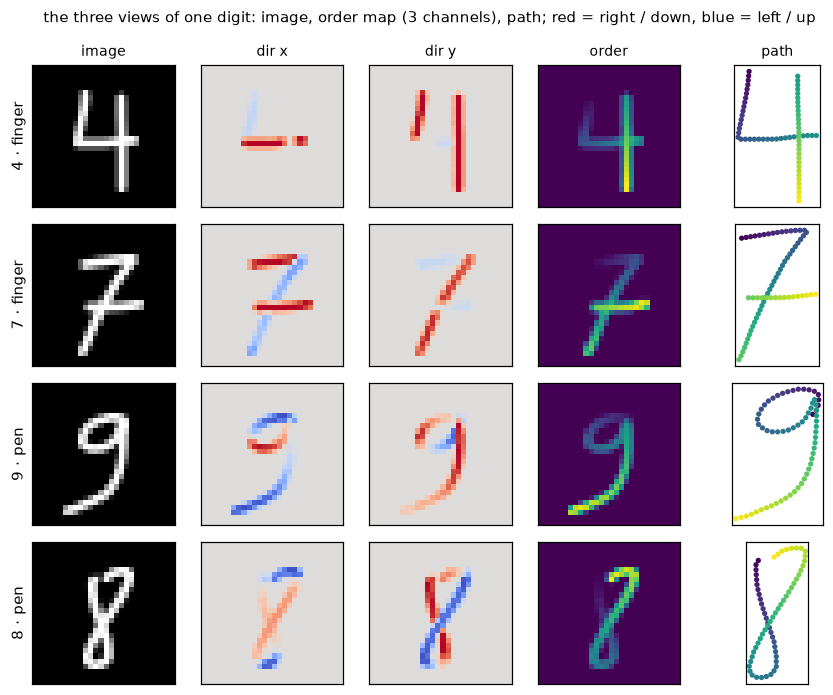

In [3]:
fig, axes = plt.subplots(4, 5, figsize=(8, 6.4))
titles = ['image', 'dir x', 'dir y', 'order']
for r, i in enumerate([SPLITS['test: finger'][j] for j in (7, 21)] + [SPLITS['test: pen'][j] for j in (3, 40)]):
    for c, (img, kw) in enumerate([(V['real_img'][i], dict(cmap='gray')),
                                   (V['real_om'][i][..., 0], dict(cmap='coolwarm', vmin=-1, vmax=1)),
                                   (V['real_om'][i][..., 1], dict(cmap='coolwarm', vmin=-1, vmax=1)),
                                   (V['real_om'][i][..., 2], dict(cmap='viridis', vmin=0, vmax=1))]):
        ax = axes[r, c]
        ax.imshow(np.asarray(img, np.float32), **kw); ax.set_xticks([]); ax.set_yticks([])
        if r == 0: ax.set_title(titles[c], fontsize=9)
    e = V['real_tr'][i]
    ax = axes[r, 4]; ax.scatter(e[:, 0], e[:, 1], c=np.arange(64), cmap='viridis', s=6); ax.invert_yaxis(); ax.set_aspect('equal')
    ax.set_xticks([]); ax.set_yticks([]); ax.set_title('path' if r == 0 else '', fontsize=9)
    axes[r, 0].set_ylabel(f'{y[i]} · {meta.device[i]}')
plt.suptitle('the three views of one digit: image, order map (3 channels), path; red = right / down, blue = left / up', fontsize=10)
plt.tight_layout(); plt.show()

## 2. 训练三个联合模型

模型存在 `cache/models/joint12b_<结构>_s<种子>.keras`。

In [4]:
x_mn, y_mn, _, _ = datasets.load_mnist()
x_mn = x_mn.astype(np.float32) / 255
skel, y_skel = ship.skeleton_sets(None, None, 'skel_train', seed=1, pens=True)
IMAGE_SOURCES = [(x_mn, y_mn, models.augment_mnist, 0.35), (skel['area18'], y_skel, models.augment_light, 0.35)]
PAIRED = [(V['pen_img'], V['pen_om'], V['pen_tr'], V['pen_y'], 0.2), (V['tmpl_img'], V['tmpl_om'], V['tmpl_tr'], V['tmpl_y'], 0.1)]

def train_joint(name, seed):
    path = MODEL_DIR / f'joint12b_{name}_s{seed}.keras'
    if path.exists():
        return keras.models.load_model(path), None
    keras.utils.set_random_seed(seed)
    ds = multiview.joint_ds(IMAGE_SOURCES, PAIRED, archs.JOINT_INPUTS[name], batch=recipe.BATCH, seed=seed)
    t0 = time.time()
    m = recipe.compile_and_fit(archs.JOINT_BUILDERS[name](), ds, seed)
    m.save(path)
    return m, time.time() - t0

real_om = V['real_om'].astype(np.float32); real_tr = V['real_tr'].astype(np.float32)
P, PJ0, rows, joint = {}, {}, [], {}
for name in archs.JOINT_BUILDERS:
    for seed in SEEDS:
        m, secs = train_joint(name, seed)
        joint[(name, seed)] = m
        keys = archs.JOINT_INPUTS[name]
        P[(name, seed)] = m.predict(multiview.eval_inputs(x_real, real_om, real_tr, keys, 1.0), batch_size=1024, verbose=0)
        PJ0[(name, seed)] = m.predict(multiview.eval_inputs(x_real, real_om, real_tr, keys, 0.0), batch_size=1024, verbose=0)
        r = {'model': name, 'seed': seed, 'params': m.count_params(), 'train min': None if secs is None else round(secs / 60, 1)}
        r.update({k: 100 * float((P[(name, seed)][idx].argmax(1) == y[idx]).mean()) for k, idx in SPLITS.items()})
        rows.append(r); print(name, seed, {k: round(v, 2) for k, v in r.items() if isinstance(v, float)})

ordermap_cnn 42 {'val: pen': 99.73, 'val: finger': 98.4, 'test: pen': 98.97, 'test: finger': 98.35}


ordermap_cnn 43 {'val: pen': 99.73, 'val: finger': 98.32, 'test: pen': 98.86, 'test: finger': 98.23}


dual_stream 42 {'val: pen': 99.73, 'val: finger': 98.53, 'test: pen': 99.29, 'test: finger': 98.27}


dual_stream 43 {'val: pen': 99.67, 'val: finger': 98.51, 'test: pen': 99.03, 'test: finger': 98.42}


ink_glance 42 {'val: pen': 99.67, 'val: finger': 99.22, 'test: pen': 98.94, 'test: finger': 99.08}


ink_glance 43 {'val: pen': 99.67, 'val: finger': 99.06, 'test: pen': 99.14, 'test: finger': 99.27}


## 3. 对照组：09 的图像模型和 11 的晚期融合；以及门控融合

门控融合：$w(x) = \sigma(\theta_0 + \theta_1 \log p^{\max}_\text{img} + \theta_2 \log p^{\max}_\text{traj} + \theta_3 H_\text{img} + \theta_4 H_\text{traj} + \theta_5 [\text{两者答案相同}])$，其中 $H$ 是熵。6 个参数在**验证数据**上拟合（让融合后的正确答案概率最大，触控笔和手指两个验证集各占一半），和 notebook 11 在验证集上选 $w$ 是同一种用法。特征先标准化，并加一个小的 L2 惩罚：第一次运行时没有惩罚，参数漂到上千，门变成了非 0 即 1 的开关，在验证集上过拟合。

In [5]:
P9 = dict(np.load(REAL / 'probs09.npz'))
r11 = json.loads((RESULTS / '11_trajectory_and_fusion.json').read_text(encoding='utf-8'))
W11 = r11['fusion_weight']; traj_name = r11['trajectory_chosen'].replace(' + ', '_')
PT = {s: keras.models.load_model(MODEL_DIR / f'traj11_{traj_name}_s{s}.keras').predict(real_tr, batch_size=2048, verbose=0) for s in SEEDS}

def fuse(p_img, p_traj, w):
    w = np.asarray(w, float).reshape(-1, 1) if np.ndim(w) else w
    z = w * np.log(p_img + 1e-7) + (1 - w) * np.log(p_traj + 1e-7)
    e = np.exp(z - z.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)

def gate_features(pi, pt):
    H = lambda p: -(p * np.log(p + 1e-7)).sum(1)
    return np.stack([np.ones(len(pi)), np.log(pi.max(1)), np.log(pt.max(1)), H(pi), H(pt), (pi.argmax(1) == pt.argmax(1)).astype(float)], 1)

def fit_gate(pi, pt, l2=0.01):
    """Logistic gate on standardised features, fitted on the validation data with a small L2 penalty
    (without it the fit drifts to huge weights, i.e. a hard switch that overfits the validation set)."""
    val = np.concatenate([SPLITS['val: pen'], SPLITS['val: finger']])
    f = gate_features(pi[val], pt[val])
    mu, sd = f[:, 1:].mean(0), f[:, 1:].std(0) + 1e-6
    def gate(p_i, p_t, th):
        g = gate_features(p_i, p_t); g[:, 1:] = (g[:, 1:] - mu) / sd
        return 1 / (1 + np.exp(-g @ th))
    def loss(th):
        out = 0
        for k in ['val: pen', 'val: finger']:
            idx = SPLITS[k]
            out += -np.log(fuse(pi[idx], pt[idx], gate(pi[idx], pt[idx], th))[np.arange(len(idx)), y[idx]] + 1e-9).mean()
        return out / 2 + l2 * np.sum(th[1:] ** 2)
    th = minimize(loss, np.zeros(6), method='L-BFGS-B').x
    return th, lambda p_i, p_t: gate(p_i, p_t, th)

THETA = {}
for s in SEEDS:
    pi, pt = P9[f'C_{s}'], PT[s]
    THETA[s], gate = fit_gate(pi, pt)
    P[('image C (09)', s)] = pi
    P[('trajectory (11)', s)] = pt
    P[('late fusion (11)', s)] = fuse(pi, pt, W11)
    P[('gated fusion', s)] = fuse(pi, pt, gate(pi, pt))
    for nm in ['image C (09)', 'trajectory (11)', 'late fusion (11)', 'gated fusion']:
        rows.append({'model': nm, 'seed': s, **{k: 100 * float((P[(nm, s)][idx].argmax(1) == y[idx]).mean()) for k, idx in SPLITS.items()}})
print('gate parameters on standardised features (seed 42):', np.round(THETA[42], 2))

gate parameters on standardised features (seed 42): [ 1.96  0.14 -0.14 -0.21  0.14  0.04]


### 3.1 再加一种组合：联合模型 + 轨迹模型的晚期融合

如果联合模型已经用上了笔迹，再和独立的轨迹模型融合还有没有收益？对每个联合模型，$w$ 在验证集上重新选。

In [6]:
WS = np.round(np.arange(0, 1.0001, 0.05), 2)
acc = lambda p, idx: 100 * float((p[idx].argmax(1) == y[idx]).mean())
W_JT = {}
for name in archs.JOINT_BUILDERS:
    val = [np.mean([acc(fuse(P[(name, s)], PT[s], w), SPLITS[k]) for s in SEEDS for k in ['val: pen', 'val: finger']]) for w in WS]
    W_JT[name] = float(WS[int(np.argmax(val))])
    for s in SEEDS:
        nm = f'{name} + trajectory'
        P[(nm, s)] = fuse(P[(name, s)], PT[s], W_JT[name])
        rows.append({'model': nm, 'seed': s, **{k: acc(P[(nm, s)], idx) for k, idx in SPLITS.items()}})
print('w per joint model:', W_JT)

w per joint model: {'ordermap_cnn': 0.65, 'dual_stream': 0.95, 'ink_glance': 1.0}


## 4. 结果

两个种子的平均。`networks` 是上线时要跑的网络个数。

In [7]:
runs = pd.DataFrame(rows)
cols = list(SPLITS)
mean = runs.groupby('model', sort=False)[cols].mean()
mean['val mean'] = mean[['val: pen', 'val: finger']].mean(axis=1)
mean['networks'] = [1 if m in archs.JOINT_BUILDERS or m in ('image C (09)', 'trajectory (11)') else 2 for m in mean.index]
base = mean.loc['image C (09)']
for k in ['test: pen', 'test: finger']:
    mean[f'{k} error cut %'] = 100 * (1 - (100 - mean[k]) / (100 - base[k]))
mean.round(2)

,val: pen,val: finger,test: pen,test: finger,val mean,networks,test: pen error cut %,test: finger error cut %
model,,,,,,,,
ordermap_cnn,99.73,98.36,98.91,98.29,99.04,1,40.63,-39.65
dual_stream,99.70,98.52,99.16,98.35,99.11,1,53.91,-34.99
ink_glance,99.67,99.14,99.04,99.17,99.40,1,47.66,32.36
image C (09),99.57,98.78,98.17,98.78,99.17,1,0.00,0.00
trajectory (11),98.16,96.79,98.21,96.96,97.48,1,2.34,-148.69
late fusion (11),99.73,99.16,99.00,99.23,99.45,2,45.31,36.73
gated fusion,99.67,99.12,98.93,99.13,99.40,2,41.41,28.86
ordermap_cnn + trajectory,99.73,98.78,99.13,98.63,99.26,2,52.34,-11.95
dual_stream + trajectory,99.70,98.53,99.07,98.34,99.11,2,49.22,-35.57


### 4.1 没有笔迹时：联合模型退回只看图像

同样的联合模型，把笔迹全部藏起来（`avail = 0`）。如果和 09 的图像模型差不多，说明 ModDrop 起作用了：一个模型两种用法。

In [8]:
img_only = pd.DataFrame([{'model': nm, 'seed': s, **{k: acc(PJ0[(nm, s)], idx) for k, idx in SPLITS.items()}}
                         for (nm, s) in PJ0]).groupby('model', sort=False)[cols].mean()
img_only.loc['image C (09)'] = mean.loc['image C (09)', cols]
img_only.round(2)

,val: pen,val: finger,test: pen,test: finger
model,,,,
ordermap_cnn,99.40,98.73,97.76,98.63
dual_stream,99.40,98.78,97.37,98.59
ink_glance,99.43,98.95,97.63,98.89
image C (09),99.57,98.78,98.17,98.78


## 5. 每个数字（测试集）

In [9]:
SHOW = ['image C (09)', 'late fusion (11)', 'gated fusion'] + list(archs.JOINT_BUILDERS)
def per_digit(p, idx):
    pred = p[idx].argmax(1)
    return [100 * (pred[y[idx] == c] == c).mean() for c in range(10)]
tabs = {(k.split(': ')[1], nm): np.mean([per_digit(P[(nm, s)], SPLITS[k]) for s in SEEDS], axis=0)
        for k in ['test: pen', 'test: finger'] for nm in SHOW}
digit_table = pd.DataFrame(tabs).round(1); digit_table.index.name = 'digit'
digit_table

pen                                                         \
      image C (09) late fusion (11) gated fusion ordermap_cnn dual_stream   
digit                                                                       
0            100.0            100.0        100.0         99.6       100.0   
1             98.6             99.3         99.2         99.6        99.7   
2             99.3             99.7         99.6         99.5        99.6   
3             98.8             99.4         99.4         99.4        99.0   
4             93.4             96.3         96.4         96.3        98.8   
5             99.6             99.4         99.4         99.6        99.7   
6             99.1             98.8         99.0         99.1        98.8   
7             96.4             98.4         97.9         98.1        97.3   
8             99.7            100.0        100.0        100.0       100.0   
9             97.0             98.8         98.5         98.2        98.8   

                       finger                                             \
      ink_glance image C (09) late fusion (11) gated fusion ordermap_cnn   
digit                                                                      
0          100.0         99.8             99.8         99.8         99.7   
1           99.5         97.9             98.8         98.5         98.9   
2          100.0         98.9             99.0         99.1         98.9   
3           98.7         98.4             98.5         98.5         97.1   
4           96.8         98.7             99.9         99.6         99.4   
5           99.4         99.3             99.5         99.4         98.8   
6           99.7         99.5             99.6         99.5         99.7   
7           97.9         98.9             99.5         99.4         98.3   
8          100.0         97.0             99.2         98.5         98.9   
9           98.5         99.4             98.5         98.9         93.3   

                              
      dual_stream ink_glance  
digit                         
0            99.7       99.9  
1            95.9       98.9  
2            98.4       99.1  
3            98.0       99.3  
4            99.9       99.9  
5            99.4       99.6  
6            98.6       99.6  
7            97.0       99.3  
8            99.1       99.1  
9            97.4       97.1

## 6. notebook 10 的错误类别修好了多少

每种方法用两个种子的平均概率，看 notebook 10 列出的方案 C 的 229 个测试错误还剩多少，以及新引入了多少错误。

In [10]:
audit = json.loads((RESULTS / '10_error_audit.json').read_text(encoding='utf-8'))
errs = pd.DataFrame(audit['errors']).set_index('id')
cat_col = 'final' if audit.get('reviewed') else 'screen'
test_idx = np.concatenate([SPLITS['test: pen'], SPLITS['test: finger']])
pC = np.mean([P[('image C (09)', s)] for s in SEEDS], axis=0)
fixed_rows = []
for nm in SHOW[1:] + [f'{n} + trajectory' for n in archs.JOINT_BUILDERS]:
    p = np.mean([P[(nm, s)] for s in SEEDS], axis=0)
    right = p.argmax(1) == y
    r = {'model': nm}
    for c in ['model', 'ambiguous', 'label']:
        ids = errs.index[errs[cat_col] == c]
        r[f'{c}: fixed / {len(ids)}'] = int(right[ids].sum())
    r['new errors'] = int(((pC[test_idx].argmax(1) == y[test_idx]) & ~right[test_idx]).sum())
    r['test errors left'] = int((~right[test_idx]).sum())
    fixed_rows.append(r)
pd.DataFrame(fixed_rows).set_index('model')

,model: fixed / 152,ambiguous: fixed / 70,label: fixed / 7,new errors,test errors left
model,,,,,
late fusion (11),95,37,1,38,134
gated fusion,76,31,0,28,150
ordermap_cnn,84,27,0,144,262
dual_stream,116,42,1,170,240
ink_glance,114,44,1,52,122
ordermap_cnn + trajectory,102,37,1,120,209
dual_stream + trajectory,117,43,1,177,245
ink_glance + trajectory,114,44,1,52,122


## 7. 在游戏规则下（屏幕上 3 个答案，种子 42）

In [11]:
game = []
for k in ['test: pen', 'test: finger']:
    idx = SPLITS[k]
    for nm in SHOW:
        a_, w_, o_ = evaluate.game_hit_rate(P[(nm, 42)][idx], y[idx], n_answers=3, seed=8)
        game.append({'test set': k, 'model': nm, 'accepted %': 100 * a_, 'wrong yokai %': 100 * w_, 'rewrite / miss %': 100 * o_})
pd.DataFrame(game).round(2)

,test set,model,accepted %,wrong yokai %,rewrite / miss %
0,test: pen,image C (09),98.71,0.43,0.86
1,test: pen,late fusion (11),99.23,0.23,0.54
2,test: pen,gated fusion,99.09,0.23,0.69
3,test: pen,ordermap_cnn,99.23,0.17,0.60
4,test: pen,dual_stream,99.40,0.23,0.37
5,test: pen,ink_glance,99.09,0.29,0.63
6,test: finger,image C (09),99.19,0.29,0.53
7,test: finger,late fusion (11),99.56,0.16,0.27
8,test: finger,gated fusion,99.46,0.18,0.36
9,test: finger,ordermap_cnn,98.79,0.39,0.82


## 8. 大小和速度（Python 里单个样本，只做相对比较；浏览器在 12c 测）

In [12]:
def keras_ms(m, inp):
    f = tf.function(lambda t: m(t, training=False)); f(inp)
    ts = []
    for _ in range(200):
        t0 = time.perf_counter(); f(inp); ts.append(time.perf_counter() - t0)
    return 1000 * np.median(ts)

one = lambda keys: multiview.eval_inputs(x_real[:1], real_om[:1], real_tr[:1], keys, 1.0)
img_m = keras.models.load_model(MODEL_DIR / 'real09_C_s42.keras')
tr_m = keras.models.load_model(MODEL_DIR / f'traj11_{traj_name}_s42.keras')
cost = [{'model': 'image C (09)', 'params': img_m.count_params(), 'ms': keras_ms(img_m, x_real[:1, ..., None])},
        {'model': 'trajectory (11)', 'params': tr_m.count_params(), 'ms': keras_ms(tr_m, real_tr[:1])}]
for name in archs.JOINT_BUILDERS:
    m = joint[(name, 42)]
    cost.append({'model': name, 'params': m.count_params(), 'ms': keras_ms(m, one(archs.JOINT_INPUTS[name]))})
cost = pd.DataFrame(cost).set_index('model')
cost.loc['late / gated fusion (2 networks)'] = cost.loc['image C (09)'] + cost.loc['trajectory (11)']
cost['weights KB (float32)'] = (cost.params * 4 / 1024).round()
cost.round(2)

,params,ms,weights KB (float32)
model,,,
image C (09),106730,11.52,417.0
trajectory (11),116730,7.98,456.0
ordermap_cnn,107882,10.92,421.0
dual_stream,222810,13.57,870.0
ink_glance,243738,15.74,952.0
late / gated fusion (2 networks),223460,19.50,873.0


## 9. 保存

In [13]:
out = {'runs': runs.to_dict(orient='records'), 'mean': mean.round(3).to_dict(orient='index'),
       'image_only_mode': img_only.round(3).to_dict(orient='index'), 'gate_theta': {s: t.tolist() for s, t in THETA.items()},
       'w_joint_plus_trajectory': W_JT, 'audit_fixed': fixed_rows, 'game_3_answers': game,
       'per_digit_test_percent': {f'{a} | {b}': v.tolist() for (a, b), v in digit_table.items()},
       'cost': cost.round(3).reset_index().to_dict(orient='records'),
       'data': {'mnist': 0.35, 'skeleton': 0.35, 'pen (paired)': 0.2, 'templates (paired)': 0.1, 'moddrop': 0.3}, 'seeds': SEEDS}
(RESULTS / '12b_new_architectures.json').write_text(json.dumps(out, indent=1, default=float), encoding='utf-8')
np.savez_compressed(REAL / 'probs12b.npz', **{f'{a}|{s}': p for (a, s), p in P.items()})
print('saved results/12b_new_architectures.json and cache/real/probs12b.npz')

saved results/12b_new_architectures.json and cache/real/probs12b.npz


## 10. 结论

**1. 交叉注意力（`ink_glance`，我们的设计）用一个网络达到了两个网络晚期融合的水平。**

| 测试集 | 图像 C（09） | 晚期融合（11，2 个网络） | **ink_glance（1 个网络）** |
|---|---|---|---|
| 触控笔 | 98.17% | 99.00% | **99.04%** |
| 手指（没训练过） | 98.78% | 99.23% | **99.17%** |

两个测试集上和晚期融合的差距都在种子波动范围内（ink_glance 两个种子：触控笔 98.94 / 99.14，手指 99.08 / 99.27）。notebook 10 的 229 个错误剩 122 个（晚期融合剩 134 个）；游戏里打错妖怪的比例和晚期融合相当（手指 0.20% 对 0.16%）。代价：24.4 万参数，和晚期融合的两个网络加起来差不多（952 KB 对 873 KB），**优势是只跑一个网络、只有一个文件，而不是更小**。再和独立的轨迹模型融合已经没有收益（验证集选出的权重是 $w = 1$，即不用轨迹模型）。

**2. 方向图 CNN 和双流联合训练：触控笔上最好，换到手指反而变差。**双流在触控笔上是所有方法里最好的（99.16%，触控笔的 4 从 93.4% 到 98.8%，那位固定写法的书写者也基本认对了），方向图 CNN 也有 98.91%；但两者在手指上都只有 98.3%，比只用图像（98.78%）还差，错误多了约 35–40%。双流在手指的 1 上只有 95.9%，方向图在手指的 9 上只有 93.3%。

**我的解释（假设，还没有单独验证）：**联合训练时，带笔迹的训练样本只来自 24 位触控笔书写者和模板，模型学会了直接依赖他们的笔顺和方向习惯（"捷径"），这些习惯在手指书写者身上不成立。晚期融合的图像模型是单独训练的，不会被笔迹带偏，融合时图像还占 55% 的权重。ink_glance 里笔迹主要用来决定"去图像哪里看"，分类的证据主要来自图像特征，所以受影响小。如果以后有更多不同工具、不同书写者的笔迹数据（尤其是你采集的手指和鼠标数据），方向图 CNN 和双流的问题可能会消失，届时值得重新比较。这也说明了一个方法论上的结论：**只在一种工具上评估会选错模型**；如果只看触控笔测试集，我们会选双流。

**3. ModDrop 起作用了：没有笔迹时，联合模型基本退回普通图像模型。**三个联合模型把笔迹藏起来后，手指 98.6–98.9%（图像 C 是 98.78%），触控笔 97.4–97.8%（图像 C 是 98.17%，略差）。所以如果某种输入方式拿不到笔迹，同一个模型仍然可用。

**4. 门控融合没有比固定权重更好。**加了 L2 惩罚后，学到的门基本是常数（偏置 1.96，其他参数都在 ±0.2 以内，即大多数样本 $w \approx 0.88$，更偏向图像），测试集上触控笔 98.93%、手指 99.13%，略低于固定 $w = 0.55$ 的 99.00%、99.23%。第一次运行没有惩罚，参数漂到上千，门成了非 0 即 1 的开关，更差。结论：在这个数据量下，**按样本调整权重学不到比"固定权重"更有用的东西**。

**5. 速度。**表里的 Python 推理时间是在 notebook 12 同时训练时测的，只能看相对大小：ink_glance 比单个图像 CNN 慢约 40%，比两个网络的晚期融合快约 20%。浏览器里的实际延迟在 12c 测。

**给 12c 的候选：**晚期融合（11，2 个网络）和 ink_glance（1 个网络）在准确率上并列最好。12c 会把它们都导出到浏览器测延迟和体积，并尝试用蒸馏把它们压到上线的大小。